# Exercise 1 (10 points)

In this exercise, we will practice how to test a function in Python. Imagine you have a function `normalize_data()` that takes in a `pandas` DataFrame and normalizes each column (scales the data so that the values in each column are between 0 and 1). You want to test this function to ensure it works correctly.


```
import pandas as pd

def normalize_data(df):
    return (df - df.min()) / (df.max() - df.min())
```

Write a test function using `assert` statements to verify that:

- Each column's minimum value is 0 and maximum value is 1 after normalization.
- The function raises an error if the input is not a DataFrame.
- The function does not alter the original DataFrame.



In [1]:

import pandas as pd

def normalize_data(df):
    return (df - df.min()) / (df.max() - df.min())

def test_normalize_data():
    df = pd.DataFrame({
        'A': [10, 20, 30],
        'B': [100, 200, 300]
    })

    original_df = df.copy()
    result = normalize_data(df)

    # Check that minimum is 0 and maximum is 1
    assert (result.min() == 0).all()
    assert (result.max() == 1).all()

    # Check that invalid input raises an error
    try:
        normalize_data([1, 2, 3])
        assert False, "Expected an error"
    except (TypeError, AttributeError):
        pass

    # Check that original data is unchanged
    assert df.equals(original_df)

    print("All tests passed!")

test_normalize_data()


All tests passed!


# Exercise 2

In this exercise, we will practice data visualiation with the `credit_card_transactions_India.csv` data file. This dataset contains insights into a collection of credit card transactions made in India, offering a comprehensive look at the spending habits of Indians across the nation. From the Gender and Card type used to carry out each transaction, to which city saw the highest amount of spending and even what kind of expenses were made, this dataset paints an overall picture about how money is being spent in India today. A brief description of the features is shown below.

- `City`: The city in which the transaction took place. 
- `Date`: The date of the transaction. 
- `Card Type`: The type of credit card used for the transaction.
- `Exp Type`: The type of expense associated with the transaction. 
- `Gender`: The gender of the cardholder. 
- `Amount`: The amount of the transaction.

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`.

In [3]:

%pip install seaborn


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### Exercise 2(b) (2 points)

Read the `credit_card_transactions_India.csv` data file and create a data frame called `credit`.

In [5]:

credit = pd.read_csv("credit_card_transactions_India.csv")

credit.head()


,index,City,Date,Card Type,Exp Type,Gender,Amount
0,0,"Delhi, India",29-Oct-14,Gold,Bills,F,82475
1,1,"Greater Mumbai, India",22-Aug-14,Platinum,Bills,F,32555
2,2,"Bengaluru, India",27-Aug-14,Silver,Bills,F,101738
3,3,"Greater Mumbai, India",12-Apr-14,Signature,Bills,F,123424
4,4,"Bengaluru, India",5-May-15,Gold,Bills,F,171574


### Exercise 2(c) (3 points)

Convert `Date` to `date-time` format.

In [6]:

credit['Date'] = pd.to_datetime(credit['Date'], dayfirst=True)

credit['Date'].head()


<ipython-input-6-3d11c5441f06>:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  credit['Date'] = pd.to_datetime(credit['Date'], dayfirst=True)


0   2014-10-29
1   2014-08-22
2   2014-08-27
3   2014-04-12
4   2015-05-05
Name: Date, dtype: datetime64[us]

### Exercise 2(d) (3 points)

Select credit card transaction in `Delhi, India` and create a data frame called `Delhi`.

In [7]:

Delhi = credit[credit['City'] == 'Delhi, India']

Delhi.head()


,index,City,Date,Card Type,Exp Type,Gender,Amount
0,0,"Delhi, India",2014-10-29,Gold,Bills,F,82475
5,5,"Delhi, India",2014-09-08,Silver,Bills,F,100036
6,6,"Delhi, India",2015-02-24,Gold,Bills,F,143250
8,8,"Delhi, India",2014-03-28,Silver,Bills,F,192247
9,9,"Delhi, India",2014-09-01,Platinum,Bills,F,67932


### Exercise 2(e) (3 points)

Create a frequency table of `Card Type` of the `Delhi` data frame.

In [8]:

Delhi['Card Type'].value_counts()


Card Type
Silver       956
Signature    872
Gold         863
Platinum     791
Name: count, dtype: int64

### Exercise 2(e) (6 points)

Create a time-series plot of `Amount` based on the different `Card Type`.

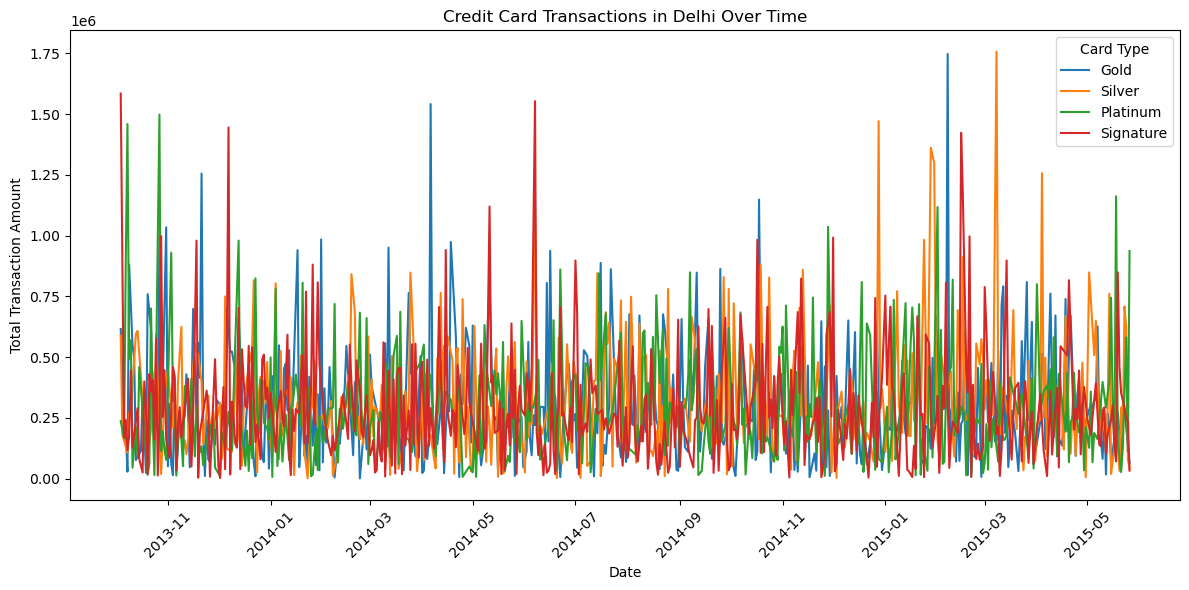

In [9]:

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=Delhi,
    x='Date',
    y='Amount',
    hue='Card Type',
    estimator='sum',
    errorbar=None
)

plt.title('Credit Card Transactions in Delhi Over Time')
plt.xlabel('Date')
plt.ylabel('Total Transaction Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Exercise 2(f) (6 points)

Create a time-series plot of `Amount` based on `Gender`.

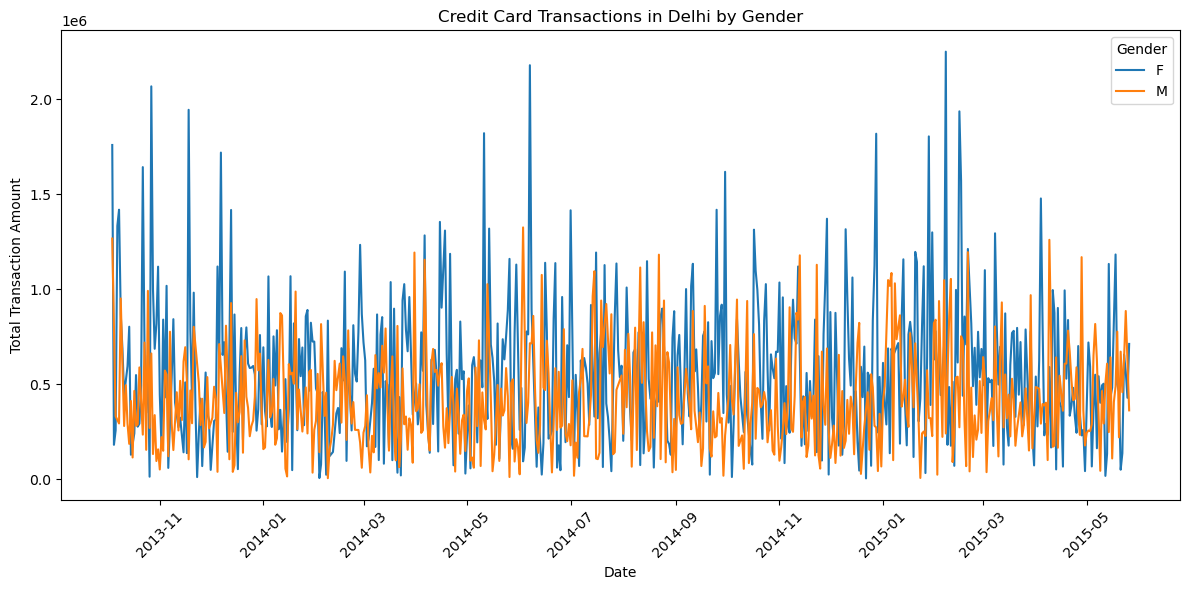

In [10]:

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=Delhi,
    x='Date',
    y='Amount',
    hue='Gender',
    estimator='sum',
    errorbar=None
)

plt.title('Credit Card Transactions in Delhi by Gender')
plt.xlabel('Date')
plt.ylabel('Total Transaction Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Exercise 3 (10 points)

Conceptual question on testing code in applied data science.

A teammate tells you: *"My data-cleaning and modeling pipeline runs without errors and the model's accuracy is 95%, so the code must be correct and I don't need to write tests."*

Do you agree? In your answer:

1. Explain why a pipeline that runs without errors and reports a high accuracy does not guarantee that the code is correct. Give at least two examples of silent bugs that could occur in a data science project (e.g., data leakage, incorrect joins, mishandled missing values).
2. Explain why testing data science code is harder than testing traditional software, and name two practices that help (e.g., fixing random seeds, using small hand-made fixtures, testing properties/invariants rather than exact values).

I disagree with my teammate. Just because the code runs without errors and shows 95% accuracy doesn't necessarily mean everything is correct. For example, the model might accidentally use information it shouldn't have access to, or data could be matched incorrectly. Missing values could also be handled the wrong way without causing an error.

Testing data science code can be harder because the results can change depending on the data being used. Two ways to make testing easier are using the same random seed to keep results consistent and testing with small datasets where we already know what the correct answers should be.

Overall, I think testing is important because it helps us catch mistakes that we might not notice otherwise.